# Cuatro sesgos inductivos, un mismo problema

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 5, unidad 2 · Genera la figura de la lámina «Qué supone un árbol»

---

La clase sostiene que márgenes, particiones y promedios no son tres niveles de
sofisticación sino **tres supuestos distintos sobre la forma del problema**.

La manera más directa de verlo es dar a todos los métodos exactamente los mismos
datos y mirar la frontera de decisión que dibuja cada uno. La frontera *es* el
sesgo inductivo, hecho imagen.

Después medimos la afirmación cuantitativa de la clase: que un árbol tiene
varianza altísima, que promediar la reduce, y que **descorrelacionar** la reduce
más.

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)
print("matplotlib   ", matplotlib.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0
matplotlib    3.10.9


## 2. Parámetros

`make_moons` produce dos medias lunas entrelazadas: una frontera **curva y
suave**, que ningún sesgo de los cuatro acierta exactamente. Eso es deliberado.
Si eligiéramos datos que favorecen a uno, el cuaderno demostraría solo que
sabemos elegir datos.

In [2]:
SEMILLA = 4
N_CASOS = 200
RUIDO = 0.28
N_REPLICAS = 60          # para medir varianza en la sección 5

X, y = make_moons(n_samples=N_CASOS, noise=RUIDO, random_state=SEMILLA)
print(f"Casos: {X.shape[0]}  |  atributos: {X.shape[1]}  |  clases: {np.bincount(y)}")

Casos: 200  |  atributos: 2  |  clases: [100 100]


## 3. Los cuatro modelos

**Los dos primeros llevan estandarización dentro de una tubería.** No es un
detalle: la distancia euclídea del kernel gaussiano depende de las escalas, así
que estandarizar es parte del modelo. Al ir dentro de la tubería, la media y la
desviación se estiman **solo con el conjunto de entrenamiento** en cualquier
validación posterior —es el ítem 4 de la lista de cotejo.

Los árboles no la necesitan: solo comparan umbrales dentro de cada atributo.

In [3]:
modelos = {
    "Regresión logística": make_pipeline(StandardScaler(),
                                         LogisticRegression()),
    "SVM con kernel RBF":  make_pipeline(StandardScaler(),
                                         SVC(C=1.0, gamma="scale")),
    "Árbol de decisión":   DecisionTreeClassifier(random_state=SEMILLA),
    "Bosque aleatorio":    RandomForestClassifier(n_estimators=300,
                                                  random_state=SEMILLA),
}

for nombre, m in modelos.items():
    m.fit(X, y)
    print(f"{nombre:22s} error de entrenamiento: {1 - m.score(X, y):.3f}")

Regresión logística    error de entrenamiento: 0.125
SVM con kernel RBF     error de entrenamiento: 0.070
Árbol de decisión      error de entrenamiento: 0.000


Bosque aleatorio       error de entrenamiento: 0.000


**El árbol tiene error de entrenamiento cero.** Es el memorizador de la semana
1: con capacidad suficiente, ERM lo elige y no avisa de nada.

## 4. Figura: la frontera *es* el sesgo

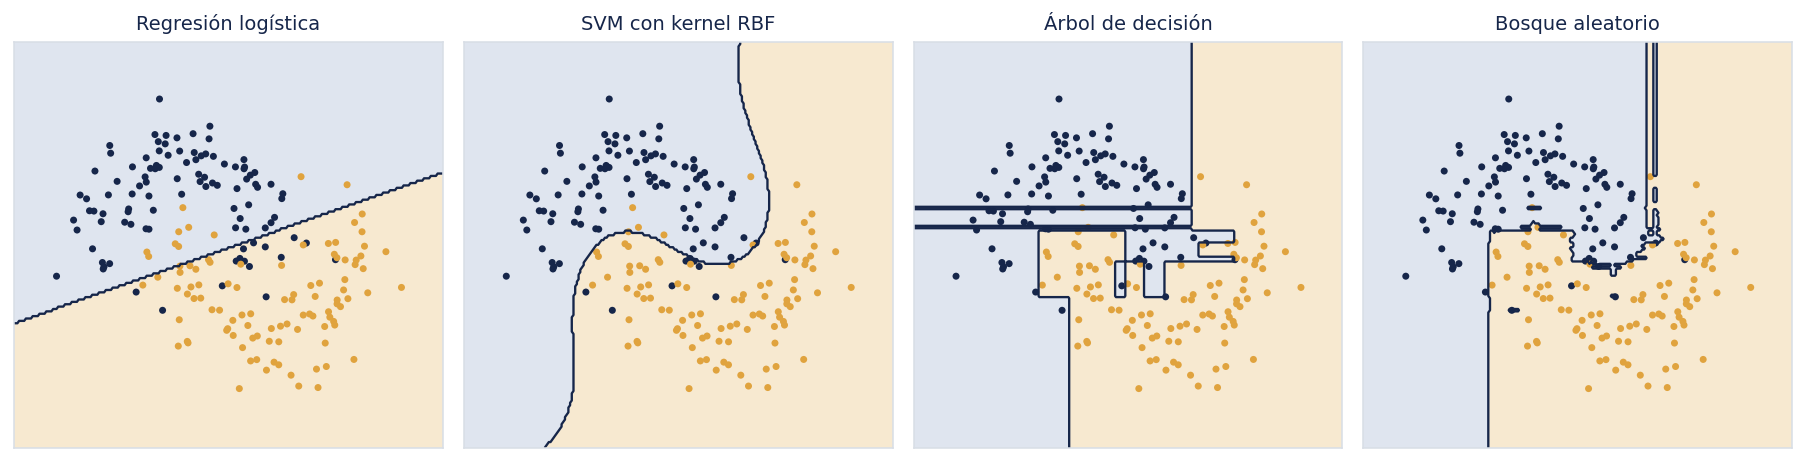

In [4]:
#| label: fig-fronteras
#| fig-cap: "Frontera de decisión de cuatro familias sobre los mismos datos."
paso = 0.02
x1 = np.arange(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, paso)
x2 = np.arange(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, paso)
XX, YY = np.meshgrid(x1, x2)
rejilla = np.c_[XX.ravel(), YY.ravel()]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), dpi=140)
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    Z = modelo.predict(rejilla).reshape(XX.shape)
    ax.contourf(XX, YY, Z, levels=[-0.5, 0.5, 1.5],
                colors=["#DCE3EE", "#F7E7CB"], alpha=0.9)
    ax.contour(XX, YY, Z, levels=[0.5], colors=["#16264A"], linewidths=1.2)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=13, c="#16264A", edgecolors="none")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=13, c="#E0A33E", edgecolors="none")
    ax.set_title(nombre, fontsize=10, color="#16264A")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color("#D8DEE6")

fig.tight_layout()
fig.savefig("fronteras_de_decision.png", dpi=200, bbox_inches="tight")
plt.show()

Lo que hay que leer, de izquierda a derecha:

- **La logística traza una recta.** No puede hacer otra cosa: su sesgo es que el
  efecto es aditivo y de pendiente constante. Con estos datos, se equivoca de
  forma sistemática y en la misma zona siempre.
- **La SVM con kernel gaussiano traza una curva suave.** Supone que la similitud
  decae con la distancia euclídea, y aquí eso es aproximadamente cierto.
- **El árbol traza una escalera.** Cortes paralelos a los ejes, con islas
  minúsculas alrededor de casos aislados —eso es la varianza, visible.
- **El bosque suaviza la escalera.** Sigue siendo paralela a los ejes en el
  fondo, pero al promediar 300 árboles las islas desaparecen.

Ninguna de las cuatro es «la correcta». La frontera verdadera es curva, así que
el kernel acierta el supuesto y el árbol no —pero eso es una propiedad de estos
datos, no del método.

## 5. La afirmación cuantitativa: varianza

La clase afirma tres cosas medibles:

1. Un árbol profundo tiene **varianza alta**: reentrenado con otra muestra,
   predice distinto.
2. **Bagging** —promediar árboles sobre remuestreos— la reduce.
3. **Descorrelacionar** —el bosque aleatorio, que además sortea atributos en cada
   corte— la reduce más.

Lo medimos como en la semana 3: muchas réplicas, y la dispersión de las
predicciones sobre un conjunto de evaluación fijo.

In [5]:
X_eval, y_eval = make_moons(n_samples=1000, noise=RUIDO, random_state=SEMILLA + 500)
rng = np.random.default_rng(SEMILLA)

def dispersión_y_error(construye):
    """Varianza de las predicciones entre réplicas, y error medio."""
    probas = np.empty((N_REPLICAS, len(X_eval)))
    errores = np.empty(N_REPLICAS)
    for r in range(N_REPLICAS):
        Xr, yr = make_moons(n_samples=N_CASOS, noise=RUIDO,
                            random_state=int(rng.integers(0, 10**6)))
        m = construye().fit(Xr, yr)
        probas[r] = m.predict_proba(X_eval)[:, 1]
        errores[r] = 1 - m.score(X_eval, y_eval)
    return probas.var(axis=0).mean(), errores.mean()

configuraciones = {
    "Árbol único":                lambda: DecisionTreeClassifier(),
    "Bagging de 300 árboles":     lambda: BaggingClassifier(
                                      DecisionTreeClassifier(), n_estimators=300),
    "Bosque aleatorio de 300":    lambda: RandomForestClassifier(n_estimators=300),
}

resultados = {}
for nombre, f in configuraciones.items():
    v, e = dispersión_y_error(f)
    resultados[nombre] = (v, e)
    print(f"{nombre:26s} varianza {v:.4f}   error medio {e:.3f}")

Árbol único                varianza 0.0586   error medio 0.111


Bagging de 300 árboles     varianza 0.0147   error medio 0.090


Bosque aleatorio de 300    varianza 0.0122   error medio 0.088


In [6]:
v_arbol = resultados["Árbol único"][0]
print()
for nombre, (v, e) in resultados.items():
    print(f"{nombre:26s} varianza relativa al árbol único: {v / v_arbol:6.1%}")


Árbol único                varianza relativa al árbol único: 100.0%
Bagging de 300 árboles     varianza relativa al árbol único:  25.1%
Bosque aleatorio de 300    varianza relativa al árbol único:  20.7%


Se ve lo que predice la teoría: **bagging reduce la varianza, y el bosque la
reduce todavía más** al descorrelacionar los árboles.

Y la fórmula de la clase explica por qué bagging no llega más lejos:

$$\operatorname{Var}\!\left(\frac{1}{B}\sum_b \hat h_b\right)=\rho\,\sigma^2+\frac{1-\rho}{B}\sigma^2\;\xrightarrow[B\to\infty]{}\;\rho\,\sigma^2$$

Con $B=300$ el segundo término ya es despreciable, así que **lo único que queda
es $\rho\sigma^2$**. Añadir más árboles no ayuda; bajar $\rho$ sí. Eso es
exactamente lo que hace el bosque aleatorio al sortear atributos en cada corte,
y es la idea de Breiman que se discute hoy en el seminario.

## 6. Bitácora

**Decisiones tomadas**

1. *`make_moons` en vez de datos reales.* La frontera verdadera se conoce y es
   curva, de modo que se puede afirmar cuál sesgo es correcto y cuál no. Con
   datos reales solo se podría comparar rendimiento, que es otra cosa.
2. *Ruido 0,28.* Con menos, las cuatro fronteras separan igual de bien y la
   figura no dice nada; con mucho más, las clases se solapan y todas fallan.
3. *Estandarización dentro de la tubería, no antes.* Aplicada al conjunto
   completo sería fuga de información en cuanto hubiera validación. Dentro de la
   tubería, se reestima en cada pliegue.
4. *Varianza medida sobre `predict_proba` y no sobre la clase predicha.* La
   probabilidad es continua y su dispersión es informativa; la clase es binaria y
   su varianza está acotada por 0,25, lo que comprime las diferencias.
5. *300 estimadores.* Suficiente para que el término $(1-\rho)\sigma^2/B$ sea
   despreciable, que es lo que permite atribuir la diferencia entre bagging y
   bosque exclusivamente a $\rho$.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró ajustar los hiperparámetros de cada familia por validación cruzada
antes de comparar, para que la comparación fuera «justa». **Se descartó** porque
cambiaría la pregunta: el cuaderno no compara rendimientos —eso exigiría el
protocolo de la unidad 3 y una prueba estadística—, sino que **exhibe la forma
del sesgo inductivo** de cada familia. Con hiperparámetros ajustados las cuatro
fronteras se parecerían más, y el punto pedagógico se perdería. Comparar
rendimiento correctamente es el taller 4, en la semana 8.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 7. Verificación

In [7]:
# 1. El árbol memoriza: error de entrenamiento nulo.
arbol = DecisionTreeClassifier(random_state=SEMILLA).fit(X, y)
assert 1 - arbol.score(X, y) == 0.0

# 2. La logística no puede separar medias lunas: su error de entrenamiento no es nulo.
logis = make_pipeline(StandardScaler(), LogisticRegression()).fit(X, y)
assert 1 - logis.score(X, y) > 0.05

# 3. Promediar reduce la varianza, y descorrelacionar la reduce más.
v_arbol = resultados["Árbol único"][0]
v_bag   = resultados["Bagging de 300 árboles"][0]
v_bosque = resultados["Bosque aleatorio de 300"][0]
assert v_bag < v_arbol,  "Bagging debería reducir la varianza."
assert v_bosque < v_bag, "El bosque debería reducirla más que bagging."

print("Verificado:")
print(f"  - el árbol memoriza (error de entrenamiento 0);")
print(f"  - la logística no separa estos datos (error {1 - logis.score(X, y):.3f});")
print(f"  - varianza: árbol {v_arbol:.4f} > bagging {v_bag:.4f} > bosque {v_bosque:.4f}.")

Verificado:
  - el árbol memoriza (error de entrenamiento 0);
  - la logística no separa estos datos (error 0.125);
  - varianza: árbol 0.0586 > bagging 0.0147 > bosque 0.0122.
